# 04 — Phân chia tập dữ liệu theo trận (Match-Level Split)

## 1. Mục tiêu
Notebook này giải thích và trực quan hóa **Bước 4** trong quy trình XAI-Football:
- Chiến lược phân chia: **BẮT BUỘC phân chia theo TRẬN ĐẤU (match-level)**, tuyệt đối không phân chia ngẫu nhiên theo possession.
- Lý do: Các possession trong cùng một trận chịu ảnh hưởng chung bởi chiến thuật đối đầu, thời tiết, phong độ và đội hình; phân chia theo possession sẽ gây rò rỉ dữ liệu (data leakage) nghiêm trọng.
- Phân tầng (Stratified split) theo tỉ lệ nhãn dương của từng trận để đảm bảo tỉ lệ nhãn dương cân bằng giữa 3 tập Train (70%), Validation (15%), và Test (15%).
- So sánh thống kê cấp độ possession ban đầu (`split_summary.csv`) và thống kê cấp độ đồ thị thực tế sau khi dựng graph (`graph_split_summary.csv`).
- Kiểm tra tính độc lập (disjointness) và chống rò rỉ dữ liệu.

## 2. Vị trí của bước trong pipeline
Đây là **Bước 4 — Chia tập train/val/test (`scripts/05_make_splits.py`, `src/xai_football/data/splits.py`)**.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Gốc repo: chạy được cả khi kernel đứng ở notebooks/ (mặc định của Jupyter/nbconvert)
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "configs").is_dir())
figures_dir = REPO_ROOT / "results" / "figures" / "official"
figures_dir.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["figure.dpi"] = 150

## 3. Input và nguồn dữ liệu
- Danh sách trận đấu: `data/splits/train_matches.csv`, `val_matches.csv`, `test_matches.csv`.
- Bảng tóm tắt phân chia cấp độ possession ban đầu: `results/tables/official/split_summary.csv`.
- Bảng tóm tắt phân chia cấp độ đồ thị thực tế: `results/tables/official/graph_split_summary.csv`.
- Bảng kiểm tra rò rỉ dữ liệu: `results/tables/official/split_checks.csv`.

## 4. Config/script/module sử dụng
- Cấu hình: `configs/split.yaml`
- Script: `scripts/05_make_splits.py`
- Module: `src/xai_football/data/splits.py`.

## 5. Các bước xử lý & Kiểm tra dữ liệu đầu vào

In [2]:
poss_summary_path = REPO_ROOT / "results" / "tables" / "official" / "split_summary.csv"
graph_summary_path = REPO_ROOT / "results" / "tables" / "official" / "graph_split_summary.csv"
checks_path = REPO_ROOT / "results" / "tables" / "official" / "split_checks.csv"

for p in [poss_summary_path, graph_summary_path]:
    if not p.exists():
        raise FileNotFoundError(f"Thiếu file: {p}. Vui lòng chạy: python scripts/05_make_splits.py --config configs/data.yaml")

df_poss_split = pd.read_csv(poss_summary_path)
df_graph_split = pd.read_csv(graph_summary_path)
df_checks = pd.read_csv(checks_path) if checks_path.exists() else pd.DataFrame()

print("=== BẢNG PHÂN CHIA CẤP ĐỘ ĐỒ THỊ THỰC TẾ (GRAPH-LEVEL SPLIT SUMMARY) ===")
display(df_graph_split)

=== BẢNG PHÂN CHIA CẤP ĐỘ ĐỒ THỊ THỰC TẾ (GRAPH-LEVEL SPLIT SUMMARY) ===


,split,n_matches,pct_matches,n_graphs,pct_graphs,n_positive,n_negative,positive_rate,n_dropped_graphs,match_overlap
0,train,266,70.0,31644,70.25,4328,27316,0.1368,220,NONE
1,val,57,15.0,6757,15.00,907,5850,0.1342,54,NONE
2,test,57,15.0,6646,14.75,918,5728,0.1381,44,NONE


## 6. Kết quả và cách diễn giải
### 6.1. So sánh số lượng trận đấu và số lượng đồ thị giữa các tập

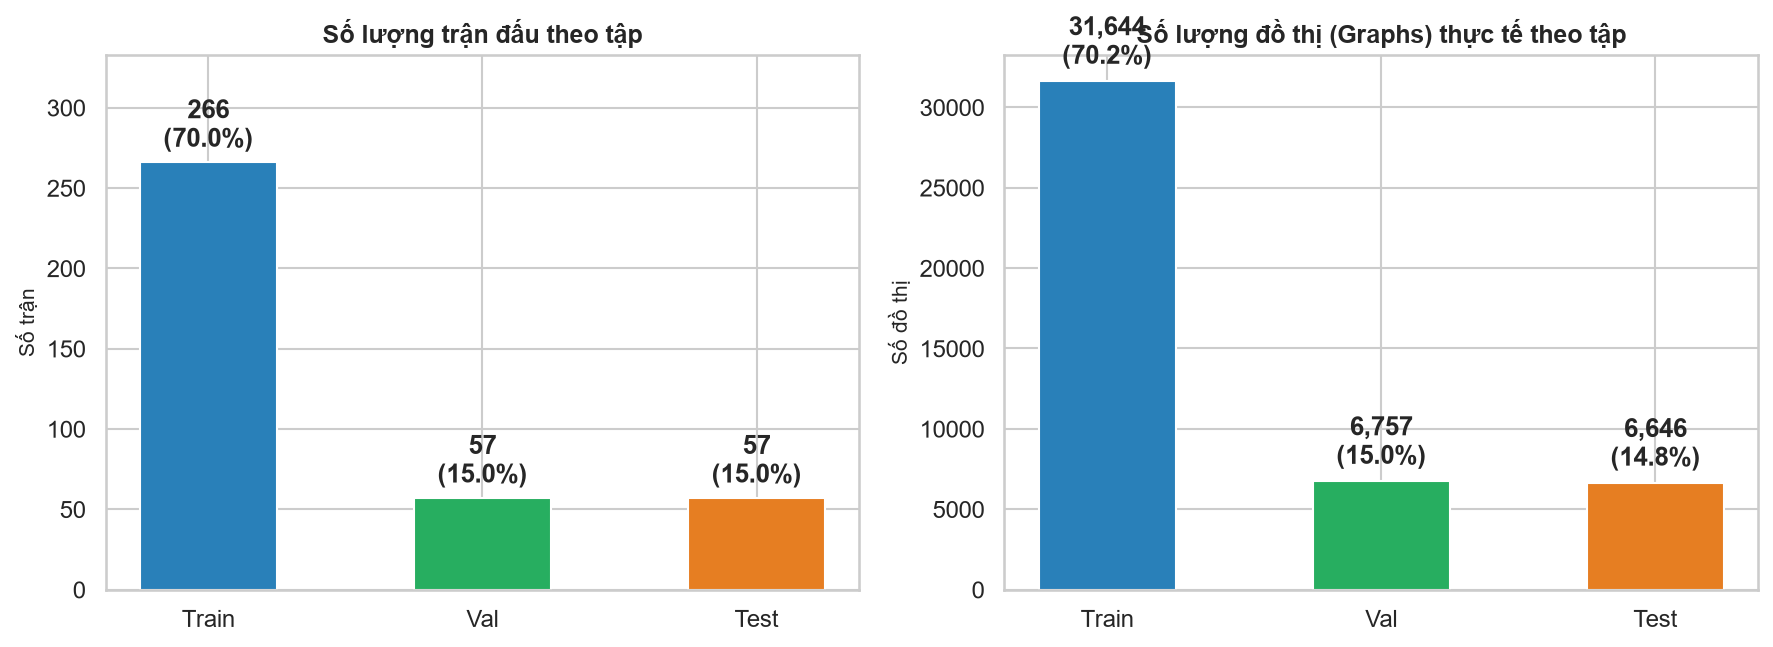

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

splits = df_graph_split["split"].str.capitalize()

# Biểu đồ số lượng trận đấu
total_matches = df_graph_split["n_matches"].sum()
bars1 = axes[0].bar(splits, df_graph_split["n_matches"], color=["#2980b9", "#27ae60", "#e67e22"], width=0.5)
axes[0].set_title("Số lượng trận đấu theo tập", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Số trận", fontsize=10)
axes[0].set_ylim(0, max(df_graph_split["n_matches"]) * 1.25)
for b in bars1:
    pct = (b.get_height() / total_matches * 100) if total_matches else 0.0
    axes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 5, f"{int(b.get_height())}\n({pct:.1f}%)", ha="center", va="bottom", fontweight="bold")

# Biểu đồ số lượng đồ thị thực tế
bars2 = axes[1].bar(splits, df_graph_split["n_graphs"], color=["#2980b9", "#27ae60", "#e67e22"], width=0.5)
axes[1].set_title("Số lượng đồ thị (Graphs) thực tế theo tập", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Số đồ thị", fontsize=10)
total_g = df_graph_split["n_graphs"].sum()
for b in bars2:
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 600, f"{int(b.get_height()):,}\n({b.get_height()/total_g*100:.1f}%)", ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.savefig(figures_dir / "04_split_distribution.png", dpi=300)
plt.savefig(figures_dir / "04_split_distribution.svg")
plt.show()

### 6.2. Kiểm tra mức độ cân bằng tỉ lệ nhãn dương giữa các tập (Stratification Balance)

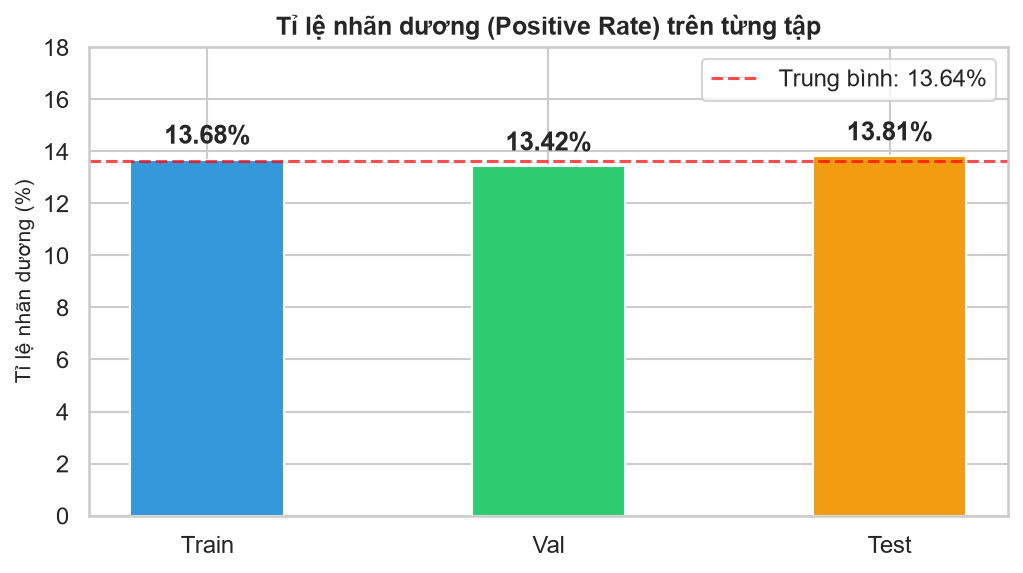

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))

rates_pct = df_graph_split["positive_rate"] * 100
bars = ax.bar(splits, rates_pct, color=["#3498db", "#2ecc71", "#f39c12"], width=0.45)
ax.set_title("Tỉ lệ nhãn dương (Positive Rate) trên từng tập", fontsize=12, fontweight="bold")
ax.set_ylabel("Tỉ lệ nhãn dương (%)", fontsize=10)
ax.set_ylim(0, 18)
ax.axhline(rates_pct.mean(), color="red", linestyle="--", alpha=0.7, label=f"Trung bình: {rates_pct.mean():.2f}%")

for b in bars:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.4, f"{b.get_height():.2f}%", ha="center", va="bottom", fontweight="bold")

ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(figures_dir / "04_split_balance.png", dpi=300)
plt.savefig(figures_dir / "04_split_balance.svg")
plt.show()

## 7. Kiểm tra chất lượng (Quality Checks) — Chống rò rỉ dữ liệu

In [5]:
print("=== BẢNG KIỂM TRA CHỐNG RÒ RỈ DỮ LIỆU (LEAKAGE CHECKS) ===")
display(df_checks)

leakage_fails = df_checks[df_checks["status"] == "FAIL"]
assert len(leakage_fails) == 0, f"Có {len(leakage_fails)} kiểm tra rò rỉ dữ liệu bị FAIL!"
print("Xác nhận: Không có match overlap nào giữa Train, Val và Test. Phân chia dữ liệu hoàn toàn sạch sẽ.")

=== BẢNG KIỂM TRA CHỐNG RÒ RỈ DỮ LIỆU (LEAKAGE CHECKS) ===


,check,value,status,note
0,no_leakage_train_val,0.0000,PASS,NaN
1,no_leakage_train_test,0.0000,PASS,NaN
2,no_leakage_val_test,0.0000,PASS,NaN
3,splits_cover_all_matches,0.0000,PASS,NaN
4,stratification_rate_balance,0.0027,PASS,Độ lệch tỉ lệ nhãn dương lớn nhất giữa các tập...


Xác nhận: Không có match overlap nào giữa Train, Val và Test. Phân chia dữ liệu hoàn toàn sạch sẽ.


## 8. Output được lưu ở đâu
- Danh sách match IDs: `data/splits/train_matches.csv`, `val_matches.csv`, `test_matches.csv`.
- Bảng tổng kết:
  - `results/tables/official/graph_split_summary.csv` (nguồn sự thật sau graph construction).
  - `results/tables/official/split_summary.csv` (possession-level trước khi truncate).
  - `results/tables/official/split_checks.csv`.
- Biểu đồ:
  - `results/figures/official/04_split_distribution.png` (và `.svg`)
  - `results/figures/official/04_split_balance.png` (và `.svg`)

## 9. Cách tái chạy
```bash
python scripts/05_make_splits.py --config configs/data.yaml
```

## 10. Giới hạn và giả định
- Cố định `seed: 42` trong `configs/split.yaml` để đảm bảo tính tái lập danh sách trận cho từng tập.
- Chia theo trận là nguyên tắc bất biến; không được chia ngẫu nhiên theo possession.